# Euler Finance: trazabilidad de una muestra de fondos
## Portfolio de investigación on-chain · Ethereum

**Autor:** Maximiliano Sosa · **Versión:** 1.0 · **Fecha de revisión:** 24 de octubre de 2026  
**Ventana de las operaciones:** 25–31 de marzo de 2023 · **Idioma:** español

Este notebook reúne el informe, el dataset manual, el análisis reproducible con Pandas y NetworkX y las capturas de evidencia. Es un estudio educativo con fuentes públicas; no es una investigación realizada para Euler, Coinbase ni un exchange.

### Resumen ejecutivo

Se reconstruyeron **siete movimientos seleccionados**, correspondientes a siete transacciones: dos de ETH y cinco de DAI. La dirección focal A02 recibió **20.344.930,50 DAI** desde dos direcciones y transfirió el mismo importe total a dos destinos, dentro de esta muestra. Una salida de **5 DAI** precedió por **3 minutos y 36 segundos** a otra de **20.000.000 DAI** hacia A04. La secuencia admite la hipótesis de una prueba previa, pero no demuestra intención ni propiedad común.

En ETH, la muestra registra **7.738,25 ETH** de A01 a A02 y **7.738,05 ETH** de A02 a A03. A03 aparece etiquetada en Etherscan como «Euler: Deployer». La última salida DAI analizada fue de **344.925,50 DAI** hacia A06, dirección publicada por Euler Foundation como tesorería de Euler DAO. A04 permanece **sin atribución validada**.

**Conclusión:** A02 funciona como punto de recepción y redistribución en el subgrafo seleccionado. Los datos y las atribuciones son compatibles con movimientos del período de devolución de fondos de Euler. La muestra no demuestra lavado de activos, identidad de los controladores, recuperación completa ni un depósito en un exchange.

### Cómo leer y ejecutar

- Para revisar el caso, leer las notas y los resultados guardados; no hace falta ejecutar código.
- En Colab, subir este `.ipynb` y elegir **Entorno de ejecución → Ejecutar todo**. Los datos y las capturas están incluidos en el notebook.
- No se necesitan claves API. La ejecución reproduce los cálculos sobre el dataset incorporado; no vuelve a descargar blockchain.
- Los archivos CSV y PNG se generan en `salidas_euler/`. El apéndice permite contrastar cada registro con su captura y su enlace público.

## 1. Objetivo y alcance

**Pregunta:** ¿cómo se conectan las entradas y salidas seleccionadas de A02, y qué puede sostenerse sobre sus contrapartes y patrones sin exceder la evidencia?

El punto inicial de revisión fue **T002**, compartida mediante su enlace en Etherscan. Se trazaron hacia atrás las entradas relevantes y hacia adelante salidas seleccionadas. Por eso el número T no expresa orden cronológico: la primera operación en el tiempo es T001.

**Incluido:** Ethereum mainnet; siete movimientos; seis direcciones económicas; ETH y DAI; cronología, conciliación de flujos de la muestra, análisis de relaciones y atribuciones públicas.

**Excluido:** reconstrucción técnica del exploit, historial completo de las direcciones, otras redes, fondos posteriores a T007, negociación privada, identificación de personas y valoración histórica en USD. No se amplía el caso para forzar la aparición de DEX, bridges o exchanges.

**Criterio de cierre:** documentar y conciliar las siete operaciones elegidas y sus límites. Esta es una muestra intencional, no exhaustiva ni aleatoria. Su tamaño permite revisión manual en un proyecto de 2–3 días; no mide el total del incidente.

## 2. Fuentes y procedencia

| Fuente | Función | Limitación |
|---|---|---|
| S01 · Etherscan, capturas T001–T007 | Hash, bloque, fecha UTC, emisor, receptor, activo, importe y estado | Explorador como interfaz; no se archivaron recibos RPC ni logs crudos |
| S02 · [Coinbase Unit 0x, 25/04/2023](https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption) | Contexto y asociación pública de A01, A02 y A05 con Euler | Sus interpretaciones no sustituyen evidencia de control; la numeración de direcciones varía dentro del artículo |
| S03 · [Euler Foundation: Treasury](https://euler.foundation/euler-DAO/treasury) | Publicación oficial de la dirección A06 | Página consultada el 24/10/2026; no acredita por sí sola la configuración histórica de firmantes |
| S04 · [Euler: relato de la recuperación](https://www.euler.finance/blog/war-peace-behind-the-scenes-of-eulers-240m-exploit-recovery) | Contexto del incidente y recuperación | Relato de una parte afectada, no dataset de este análisis |

Las capturas originales fueron aportadas por el investigador y revisadas para consolidar este notebook. Se preservan sin alterar en el apéndice y en el paquete del proyecto, con SHA-256. **El hash del archivo garantiza detección de cambios posteriores; no autentica por sí mismo su origen ni su fecha.** La fecha 24/10/2026 es la de revisión del material, no una certificación del momento de captura.

Las direcciones completas A04 y A06 se recibieron también como texto durante la revisión manual: las capturas muestran valores abreviados o etiquetas. Esto queda registrado como limitación de la evidencia visual. La publicación oficial corrobora la dirección completa A06. En esta revisión no se logró una descarga automatizada independiente de las páginas de transacción de Etherscan; la base transaccional es la transcripción de las capturas, no una consulta RPC.

Las etiquetas visibles hoy (por ejemplo, «Sky: Dai Stablecoin») no se interpretan como etiquetas históricas de 2023. Se identifica DAI mediante el contrato, no solo mediante el nombre mostrado.

## 3. Metodología y disciplina analítica

1. Registrar cada transacción con hash, bloque y hora UTC; separar los movimientos de activos de las llamadas a contratos.
2. Para ETH nativo, revisar `From`, `To` y `Value`. Para DAI, leer el movimiento en **ERC-20 Tokens Transferred**: el `Interacted With (To)` es el contrato DAI, no el destinatario económico.
3. Preservar los importes como texto decimal y calcular con `Decimal`, evitando errores de punto flotante. Separar siempre ETH y DAI; el gas se paga en ETH.
4. Ordenar por tiempo, conciliar entradas y salidas seleccionadas de A02 y construir un grafo dirigido con una arista por movimiento.
5. Registrar atribuciones aparte de los hechos. Evaluar explicaciones alternativas antes de interpretar un patrón.

| Categoría | Uso en este caso |
|---|---|
| FACT / HECHO | Dato transaccional observable, aquí obtenido de la captura del explorador y sujeto a esa limitación de fuente |
| ATTRIBUTION / ATRIBUCIÓN | Asociación de una dirección con una entidad o incidente, sustentada por una fuente externa |
| INFERENCE / INFERENCIA | Interpretación analítica, por ejemplo el papel de A02 como punto de consolidación en la muestra |
| HYPOTHESIS / HIPÓTESIS | Explicación pendiente de evidencia adicional, como una posible transferencia de prueba |

**Escala de confianza de atribución:** CONFIRMED = publicación explícita de la entidad para la afirmación concreta; HIGH CONFIDENCE = etiqueta específica o investigación pública con dirección completa; MEDIUM CONFIDENCE = indicios convergentes incompletos; LOW CONFIDENCE = indicio débil; UNKNOWN = evidencia insuficiente. Son categorías cualitativas, no probabilidades. No es necesario usar todas.

CONFIRMED para A06 significa «dirección publicada como tesorería», no «identidad confirmada de todos sus controladores». Una relación transaccional no prueba propiedad común, colaboración ni culpabilidad.

### Supuestos y precisión

Cada fila representa **un movimiento seleccionado**, no necesariamente todos los efectos de una transacción. Los importes se conservan con la precisión visible; no se verificaron unidades mínimas de ETH ni valores enteros de logs ERC-20. `log_index` permanece vacío. Para ampliar el dataset a múltiples eventos por hash, la clave deberá incorporar `chain_id + tx_hash + log_index` (o identificador de traza para movimientos internos).

No se utiliza una regla FIFO, proporcional u otra heurística de contaminación: vincular nodos no asigna automáticamente un porcentaje del importe a una fuente determinada. El neto de la muestra tampoco equivale a un saldo on-chain.

## 4. Registro de mi trabajo y asistencia

| Etapa | Trabajo documentado | Responsable / asistencia |
|---|---|---|
| Revisión manual | Apertura de transacciones en Etherscan, aporte de capturas y copia de direcciones completas | Investigador |
| Selección y tracing | Seguimiento acotado de las operaciones y consulta de resultados durante la conversación | Investigador, con orientación del asistente |
| Dataset | Transcripción de los datos visibles y revisión de coherencia | Elaboración asistida; no extracción automática de la red |
| Python y documentación | Consolidación del notebook, cálculos, grafos, controles y redacción | Asistencia de IA; debe declararse al explicar el proyecto |
| Corroboración externa | Revisión de Coinbase, Euler y publicación de la tesorería | Asistente, con enlaces auditables |

No se atribuyen horas de trabajo, revisiones o competencias no acreditadas. Las capturas documentan parte de la revisión; no prueban una investigación independiente sin asistencia. Para una entrevista, el autor debe poder explicar la diferencia entre destino del token y contrato, el cálculo de los flujos y los límites de las atribuciones.

## 5. Preparación de Python

Pandas organiza y valida los datos; `Decimal` conserva los importes; NetworkX representa relaciones; Matplotlib produce imágenes portables. No se usan Gephi, Dune ni herramientas comerciales porque no aportan una mejora necesaria para siete operaciones.

Colab suele incluir estas dependencias. Si una importación falla, ejecutar en una celda: `%pip install pandas networkx matplotlib`. El paquete incluye las versiones exactas usadas para validar esta entrega; no es necesario instalar versiones nuevas para leer las salidas guardadas.

In [1]:
from pathlib import Path
from decimal import Decimal, getcontext
import json
import re
import hashlib
import platform
import importlib.metadata as metadata
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

getcontext().prec = 78
SALIDAS = Path('salidas_euler')
SALIDAS.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':12,
                     'figure.facecolor':'white', 'axes.facecolor':'white'})

def formato(valor):
    # Formato de lectura español; el CSV conserva punto decimal sin separador de miles.
    return f'{valor:,.2f}'.replace(',', '_').replace('.', ',').replace('_', '.')

versiones = {'python':platform.python_version()}
versiones.update({p:metadata.version(p) for p in ['pandas','networkx','matplotlib']})
display(versiones)

{'python': '3.12.14',
 'pandas': '2.2.3',
 'networkx': '3.7',
 'matplotlib': '3.10.8'}

## 6. Dataset incorporado

`from_address` y `to_address` representan emisor y receptor **del activo**. `transaction_to` conserva el destinatario de la transacción externa. Los campos técnicos se mantienen en inglés para facilitar interoperabilidad; las explicaciones están en español.

`amount_usd` está vacío porque no se obtuvo una cotización histórica documentada. Tampoco se convierten DAI a dólares suponiendo paridad. `fee_eth` vacío significa no transcrito, no comisión cero. Las atribuciones se mantienen en una tabla de direcciones, para no confundir una etiqueta con un hecho transaccional.

In [2]:
registros = [{'id': 'T001',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0x79c10cf538667a0a7de40ce54d2444c9e9e17b5c62b321e739020df0015baeda',
  'block_number': 16905356,
  'timestamp': '2023-03-25T15:25:59Z',
  'from_id': 'A01',
  'to_id': 'A02',
  'from_address': '0xb66cd966670d962c227b3eaba30a872dbfb995db',
  'to_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'token': 'ETH',
  'token_contract': None,
  'amount': '7738.25',
  'amount_usd': None,
  'transaction_type': 'ETH nativo',
  'transaction_to': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'log_index': None,
  'fee_eth': '0.000549608919027',
  'status': 'Success',
  'evidence_id': 'T001',
  'source_url': 'https://etherscan.io/tx/0x79c10cf538667a0a7de40ce54d2444c9e9e17b5c62b321e739020df0015baeda',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'},
 {'id': 'T002',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d',
  'block_number': 16920430,
  'timestamp': '2023-03-27T18:13:47Z',
  'from_id': 'A02',
  'to_id': 'A03',
  'from_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'to_address': '0xee009faf00cf54c1b4387829af7a8dc5f0c8c8c5',
  'token': 'ETH',
  'token_contract': None,
  'amount': '7738.05',
  'amount_usd': None,
  'transaction_type': 'ETH nativo',
  'transaction_to': '0xee009faf00cf54c1b4387829af7a8dc5f0c8c8c5',
  'log_index': None,
  'fee_eth': '0.000900684335775',
  'status': 'Success',
  'evidence_id': 'T002',
  'source_url': 'https://etherscan.io/tx/0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'},
 {'id': 'T003',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b',
  'block_number': 16920635,
  'timestamp': '2023-03-27T18:55:11Z',
  'from_id': 'A02',
  'to_id': 'A04',
  'from_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'to_address': '0x0d1b0c32b52583fd155ea6a2df10214270da9843',
  'token': 'DAI',
  'token_contract': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'amount': '5',
  'amount_usd': None,
  'transaction_type': 'ERC20 Transfer',
  'transaction_to': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'log_index': None,
  'fee_eth': '0.001622235891971676',
  'status': 'Success',
  'evidence_id': 'T003',
  'source_url': 'https://etherscan.io/tx/0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'},
 {'id': 'T004',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0x3d0b3a04a7031841b44c94b4f9cccdc397b0f6e97f7cc2ecfcc3abe8732a995f',
  'block_number': 16920653,
  'timestamp': '2023-03-27T18:58:47Z',
  'from_id': 'A02',
  'to_id': 'A04',
  'from_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'to_address': '0x0d1b0c32b52583fd155ea6a2df10214270da9843',
  'token': 'DAI',
  'token_contract': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'amount': '20000000',
  'amount_usd': None,
  'transaction_type': 'ERC20 Transfer',
  'transaction_to': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'log_index': None,
  'fee_eth': None,
  'status': 'Success',
  'evidence_id': 'T004',
  'source_url': 'https://etherscan.io/tx/0x3d0b3a04a7031841b44c94b4f9cccdc397b0f6e97f7cc2ecfcc3abe8732a995f',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'},
 {'id': 'T005',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0x7e606bd1f8ef29cf6dc86c9c48307172985536b2039d41b2f1e672b99bbd1f78',
  'block_number': 16905373,
  'timestamp': '2023-03-25T15:29:23Z',
  'from_id': 'A01',
  'to_id': 'A02',
  'from_address': '0xb66cd966670d962c227b3eaba30a872dbfb995db',
  'to_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'token': 'DAI',
  'token_contract': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'amount': '10787465.25',
  'amount_usd': None,
  'transaction_type': 'ERC20 Transfer',
  'transaction_to': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'log_index': None,
  'fee_eth': None,
  'status': 'Success',
  'evidence_id': 'T005',
  'source_url': 'https://etherscan.io/tx/0x7e606bd1f8ef29cf6dc86c9c48307172985536b2039d41b2f1e672b99bbd1f78',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'},
 {'id': 'T006',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0x79d5a1f873c52942cc1eb681ef8f6b1005e3fcfa48db5b66e63962b6696e4845',
  'block_number': 16906198,
  'timestamp': '2023-03-25T18:16:59Z',
  'from_id': 'A05',
  'to_id': 'A02',
  'from_address': '0x46e0be2df97dac791fc8e30cf2b2e4f58c50cf55',
  'to_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'token': 'DAI',
  'token_contract': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'amount': '9557465.25',
  'amount_usd': None,
  'transaction_type': 'ERC20 Transfer',
  'transaction_to': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'log_index': None,
  'fee_eth': None,
  'status': 'Success',
  'evidence_id': 'T006',
  'source_url': 'https://etherscan.io/tx/0x79d5a1f873c52942cc1eb681ef8f6b1005e3fcfa48db5b66e63962b6696e4845',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'},
 {'id': 'T007',
  'chain': 'ethereum',
  'chain_id': 1,
  'tx_hash': '0x7debdb60baabc71c87b25ab0213dc01d0b738050bc00f22397aeb0666f0e8334',
  'block_number': 16947826,
  'timestamp': '2023-03-31T14:39:35Z',
  'from_id': 'A02',
  'to_id': 'A06',
  'from_address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'to_address': '0xcad001c30e96765ac90307669d578219d4fb1dce',
  'token': 'DAI',
  'token_contract': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'amount': '344925.50',
  'amount_usd': None,
  'transaction_type': 'ERC20 Transfer',
  'transaction_to': '0x6b175474e89094c44da98b954eedeac495271d0f',
  'log_index': None,
  'fee_eth': None,
  'status': 'Success',
  'evidence_id': 'T007',
  'source_url': 'https://etherscan.io/tx/0x7debdb60baabc71c87b25ab0213dc01d0b738050bc00f22397aeb0666f0e8334',
  'notes': 'Importe mostrado en Etherscan; sin validación contra unidades mínimas del recibo RPC.'}]

direcciones = [{'id': 'A01',
  'address': '0xb66cd966670d962c227b3eaba30a872dbfb995db',
  'rol': 'Origen asociado públicamente al incidente',
  'entity_type': 'Dirección; controlador desconocido',
  'attribution': 'Asociación pública con el incidente Euler',
  'confidence': 'HIGH CONFIDENCE',
  'source': 'https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption',
  'basis': 'Dirección completa en Appendix A; captura T001: Euler Finance Exploiter 2'},
 {'id': 'A02',
  'address': '0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676',
  'rol': 'Dirección focal',
  'entity_type': 'Dirección; controlador desconocido',
  'attribution': 'Asociación pública con el incidente Euler',
  'confidence': 'HIGH CONFIDENCE',
  'source': 'https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption',
  'basis': 'Dirección completa en Appendix A; movimientos T001–T007'},
 {'id': 'A03',
  'address': '0xee009faf00cf54c1b4387829af7a8dc5f0c8c8c5',
  'rol': 'Destino ETH',
  'entity_type': 'Dirección atribuida a Euler',
  'attribution': 'Euler: Deployer',
  'confidence': 'HIGH CONFIDENCE',
  'source': 'https://etherscan.io/tx/0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d',
  'basis': 'Etiqueta visible en captura T002; no prueba de identidad personal'},
 {'id': 'A04',
  'address': '0x0d1b0c32b52583fd155ea6a2df10214270da9843',
  'rol': 'Destino DAI',
  'entity_type': 'Desconocido',
  'attribution': 'Sin atribución validada',
  'confidence': 'UNKNOWN',
  'source': 'https://etherscan.io/tx/0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b',
  'basis': 'Receptor económico en T003/T004; dirección completa aportada manualmente'},
 {'id': 'A05',
  'address': '0x46e0be2df97dac791fc8e30cf2b2e4f58c50cf55',
  'rol': 'Segundo origen DAI',
  'entity_type': 'Dirección; controlador desconocido',
  'attribution': 'Asociación pública con el incidente Euler',
  'confidence': 'HIGH CONFIDENCE',
  'source': 'https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption',
  'basis': 'Dirección completa en Appendix A; origen en captura T006'},
 {'id': 'A06',
  'address': '0xcad001c30e96765ac90307669d578219d4fb1dce',
  'rol': 'Destino DAI',
  'entity_type': 'Tesorería / multisig',
  'attribution': 'Euler DAO Treasury',
  'confidence': 'CONFIRMED',
  'source': 'https://euler.foundation/euler-DAO/treasury',
  'basis': 'Dirección publicada por Euler Foundation; captura T007: Euler Multisig 2; dirección '
           'completa aportada manualmente'}]

manifiesto = [{'evidence_id': 'T001',
  'archivo': 'T001_etherscan.png',
  'archivo_original': 'image(20261024-173910).png',
  'sha256': '1590a2d90c47e3397eda97870ba3ca09a1ef54e37ae751eafa0c957ca8b49129',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0x79c10cf538667a0a7de40ce54d2444c9e9e17b5c62b321e739020df0015baeda'},
 {'evidence_id': 'T002',
  'archivo': 'T002_etherscan.png',
  'archivo_original': 'image(20261024-181616).png',
  'sha256': '4fdc0153e86d98c7dab8cb08433202cbc2d2e344be9475a369ced6d1b8924053',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d'},
 {'evidence_id': 'T003',
  'archivo': 'T003_etherscan.png',
  'archivo_original': 'image(20261024-184100).png',
  'sha256': '2d4917caf15f9a37432ce1d58123c78c2bbafbcba398d470b029f2b36c582827',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b'},
 {'evidence_id': 'T004',
  'archivo': 'T004_etherscan.png',
  'archivo_original': 'image(20261024-190128).png',
  'sha256': '78a650b17c66a49ef748d824543ff5435f60adfd11e7a3386b9d24e796a06a29',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0x3d0b3a04a7031841b44c94b4f9cccdc397b0f6e97f7cc2ecfcc3abe8732a995f'},
 {'evidence_id': 'T005',
  'archivo': 'T005_etherscan.png',
  'archivo_original': 'image(20261024-190733).png',
  'sha256': '385028d1a44d73cbd487d9d882cbb8a6f1acaa417e8d5c6727ef0c162aef0ad1',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0x7e606bd1f8ef29cf6dc86c9c48307172985536b2039d41b2f1e672b99bbd1f78'},
 {'evidence_id': 'T006',
  'archivo': 'T006_etherscan.png',
  'archivo_original': 'image(20261024-191100).png',
  'sha256': '1c52bf7815c08e795d9cecfa77d2b4480341033f5c2d8548cabb6c45b7b11ba9',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0x79d5a1f873c52942cc1eb681ef8f6b1005e3fcfa48db5b66e63962b6696e4845'},
 {'evidence_id': 'T007',
  'archivo': 'T007_etherscan.png',
  'archivo_original': 'image(20261024-231328).png',
  'sha256': 'fbbb94101917637da9b2b76353ec6da1605163a9cef906935d58a750cccc3df0',
  'procedencia': 'Captura aportada por el investigador en la conversación',
  'fecha_revision': '2026-10-24',
  'url': 'https://etherscan.io/tx/0x7debdb60baabc71c87b25ab0213dc01d0b738050bc00f22397aeb0666f0e8334'}]

transacciones = pd.DataFrame(registros)
transacciones["timestamp"] = pd.to_datetime(transacciones["timestamp"], utc=True)
transacciones["amount"] = transacciones["amount"].map(Decimal)
transacciones["fee_eth"] = transacciones["fee_eth"].map(lambda x: Decimal(x) if x is not None else None)
transacciones = transacciones.sort_values(["timestamp", "block_number", "id"]).reset_index(drop=True)
atribuciones = pd.DataFrame(direcciones)

### Controles de calidad

Estos controles detectan errores de formato, duplicación, direcciones desconocidas en el catálogo y contradicciones temporales. **No prueban que los datos coincidan con un nodo Ethereum.** La comprobación contra las capturas es un control separado.

In [3]:
assert transacciones['id'].is_unique, 'Identificadores repetidos'
assert transacciones['tx_hash'].is_unique, 'Revisar granularidad: hash repetido'
assert transacciones['tx_hash'].str.fullmatch(r'0x[0-9a-f]{64}').all()
for columna in ['from_address','to_address','transaction_to']:
    assert transacciones[columna].str.fullmatch(r'0x[0-9a-f]{40}').all(), columna
assert transacciones['timestamp'].notna().all()
assert transacciones['block_number'].is_monotonic_increasing
assert transacciones['amount'].map(lambda x: x > 0).all()
assert set(transacciones['token']) <= {'DAI','ETH'}
assert transacciones['status'].eq('Success').all()
catalogo = atribuciones.set_index('id')['address'].to_dict()
for fila in transacciones.itertuples():
    assert catalogo[fila.from_id] == fila.from_address
    assert catalogo[fila.to_id] == fila.to_address
    if fila.token == 'DAI':
        assert fila.transaction_to == fila.token_contract
    else:
        assert fila.transaction_to == fila.to_address
assert transacciones.loc[transacciones['token'].eq('DAI'), 'token_contract'].nunique() == 1
print('Controles de estructura y coherencia: correctos.')
print('Registros:', len(transacciones), '| Hashes:', transacciones['tx_hash'].nunique())
print('Comisiones sin transcribir:', transacciones['fee_eth'].isna().sum())
print('Índices de log sin registrar:', transacciones.loc[transacciones['token'].eq('DAI'),'log_index'].isna().sum())

Controles de estructura y coherencia: correctos.
Registros: 7 | Hashes: 7
Comisiones sin transcribir: 4
Índices de log sin registrar: 5


## 7. Cronología de transacciones

Los identificadores conservan el orden de registro; la tabla muestra el orden temporal real. Todas las horas son UTC.

In [4]:
cronologia = transacciones[['id','timestamp','block_number','from_id','to_id','token','amount']].copy()
cronologia['timestamp'] = cronologia['timestamp'].dt.strftime('%d/%m/%Y %H:%M:%S UTC')
cronologia['amount'] = cronologia['amount'].map(formato)
cronologia.columns = ['ID','Fecha UTC','Bloque','Origen','Destino','Activo','Importe']
display(cronologia)

,ID,Fecha UTC,Bloque,Origen,Destino,Activo,Importe
0,T001,25/03/2023 15:25:59 UTC,16905356,A01,A02,ETH,"7.738,25"
1,T005,25/03/2023 15:29:23 UTC,16905373,A01,A02,DAI,"10.787.465,25"
2,T006,25/03/2023 18:16:59 UTC,16906198,A05,A02,DAI,"9.557.465,25"
3,T002,27/03/2023 18:13:47 UTC,16920430,A02,A03,ETH,"7.738,05"
4,T003,27/03/2023 18:55:11 UTC,16920635,A02,A04,DAI,"5,00"
5,T004,27/03/2023 18:58:47 UTC,16920653,A02,A04,DAI,"20.000.000,00"
6,T007,31/03/2023 14:39:35 UTC,16947826,A02,A06,DAI,"344.925,50"


## 8. Conciliación de flujos seleccionados de A02

Se calculan entradas y salidas por activo. No se suman ETH con DAI. Para DAI, dos entradas financian un volumen agregado igual a las tres salidas analizadas; esto demuestra una igualdad aritmética en la muestra, no individualiza unidades fungibles ni acredita que no existieron otras operaciones.

In [5]:
FOCAL = 'A02'
resumen = []
for activo, grupo in transacciones.groupby('token'):
    entradas = sum(grupo.loc[grupo['to_id'].eq(FOCAL), 'amount'], Decimal('0'))
    salidas = sum(grupo.loc[grupo['from_id'].eq(FOCAL), 'amount'], Decimal('0'))
    resumen.append({'Activo':activo, 'Entradas':entradas, 'Salidas':salidas,
                    'Neto de la muestra':entradas-salidas})
flujos = pd.DataFrame(resumen).set_index('Activo')
display(flujos.map(formato))

,Entradas,Salidas,Neto de la muestra
Activo,,,
DAI,"20.344.930,50","20.344.930,50","0,00"
ETH,"7.738,25","7.738,05","0,20"


**Resultado:** entradas y salidas DAI de 20.344.930,50 cada una; neto de la muestra 0 DAI. Para ETH, el neto de los dos movimientos es 0,20 ETH **antes de comisiones y operaciones omitidas**. No se presenta como saldo final ni como beneficio.

La coincidencia DAI es útil para revisar la coherencia de lo seleccionado, pero no prueba completitud: movimientos omitidos podrían compensarse. T003 y T004 suman 20.000.005 DAI; T007 agrega 344.925,50 DAI.

### Intervalos relevantes

Las diferencias temporales ayudan a describir secuencias, sin establecer intención.

In [6]:
por_id = transacciones.set_index('id')
intervalos = []
for inicio, fin, lectura in [
    ('T003','T004','Mismo origen y destino DAI'),
    ('T001','T002','Entrada y salida ETH de A02'),
    ('T005','T006','Dos entradas DAI a A02')]:
    diferencia = por_id.loc[fin,'timestamp'] - por_id.loc[inicio,'timestamp']
    intervalos.append({'Desde':inicio,'Hasta':fin,'Intervalo':str(diferencia),'Lectura':lectura})
display(pd.DataFrame(intervalos))

,Desde,Hasta,Intervalo,Lectura
0,T003,T004,0 days 00:03:36,Mismo origen y destino DAI
1,T001,T002,2 days 02:47:48,Entrada y salida ETH de A02
2,T005,T006,0 days 02:47:36,Dos entradas DAI a A02


## 9. Grafo de transacciones y análisis de red

Un nodo representa una **dirección**, no una persona. Se usa `MultiDiGraph`: permite conservar T003 y T004 como dos aristas distintas entre las mismas direcciones. Cada arista retiene ID, hash, hora, activo e importe. El contrato DAI se conserva como metadato técnico; no se representa como receptor económico de los 20 millones.

El grafo analítico contiene las siete operaciones. El diagrama combina visualmente aristas paralelas y enumera sus IDs para que se lea con claridad. Posiciones, tamaños y grosor de flechas son esquemáticos: no representan valor, distancia ni riesgo.

In [7]:
grafo = nx.MultiDiGraph()
for fila in atribuciones.itertuples():
    grafo.add_node(fila.id, address=fila.address, rol=fila.rol,
                   attribution=fila.attribution, confidence=fila.confidence)
for fila in transacciones.itertuples():
    grafo.add_edge(fila.from_id, fila.to_id, key=fila.id,
                   tx_hash=fila.tx_hash, timestamp=fila.timestamp.isoformat(),
                   asset=fila.token, amount=str(fila.amount), source_url=fila.source_url)

grafo_dai = nx.MultiDiGraph()
for origen, destino, clave, datos in grafo.edges(keys=True, data=True):
    if datos['asset'] == 'DAI':
        grafo_dai.add_edge(origen, destino, key=clave, **datos)

metricas = pd.DataFrame([{
    'Nodo':nodo,
    'Entradas (operaciones DAI)':grafo_dai.in_degree(nodo),
    'Salidas (operaciones DAI)':grafo_dai.out_degree(nodo),
    'Grado total DAI':grafo_dai.degree(nodo),
    'Orígenes distintos DAI':len(set(grafo_dai.predecessors(nodo))),
    'Destinos distintos DAI':len(set(grafo_dai.successors(nodo)))
} for nodo in sorted(grafo_dai.nodes)])
assert grafo.number_of_edges() == len(transacciones), 'Se perdieron movimientos al construir el grafo'
print(f'Grafo completo: {grafo.number_of_nodes()} nodos y {grafo.number_of_edges()} movimientos.')
print(f'Subgrafo DAI: {grafo_dai.number_of_nodes()} nodos y {grafo_dai.number_of_edges()} movimientos.')
display(metricas)

Grafo completo: 6 nodos y 7 movimientos.
Subgrafo DAI: 5 nodos y 5 movimientos.


,Nodo,Entradas (operaciones DAI),Salidas (operaciones DAI),Grado total DAI,Orígenes distintos DAI,Destinos distintos DAI
0,A01,0,1,1,0,1
1,A02,2,3,5,2,2
2,A04,2,0,2,1,0
3,A05,0,1,1,0,1
4,A06,1,0,1,1,0


**Interpretación:** en DAI, A02 tiene dos operaciones de entrada, tres de salida, dos orígenes distintos y dos destinos distintos. Su grado total es cinco. Es el nodo focal por el diseño de la muestra, por lo que su alta conectividad local no acredita importancia en toda la red.

No se calculan rankings de centralidad ni comunidades: siete operaciones seleccionadas alrededor de A02 sesgarían esas métricas. Los conjuntos conectados no equivalen a clusters de propiedad. Para estudiar comunidades o centralidad haría falta un universo de datos más amplio y un criterio de muestreo defendible.

### Flujo de fondos · muestra completa

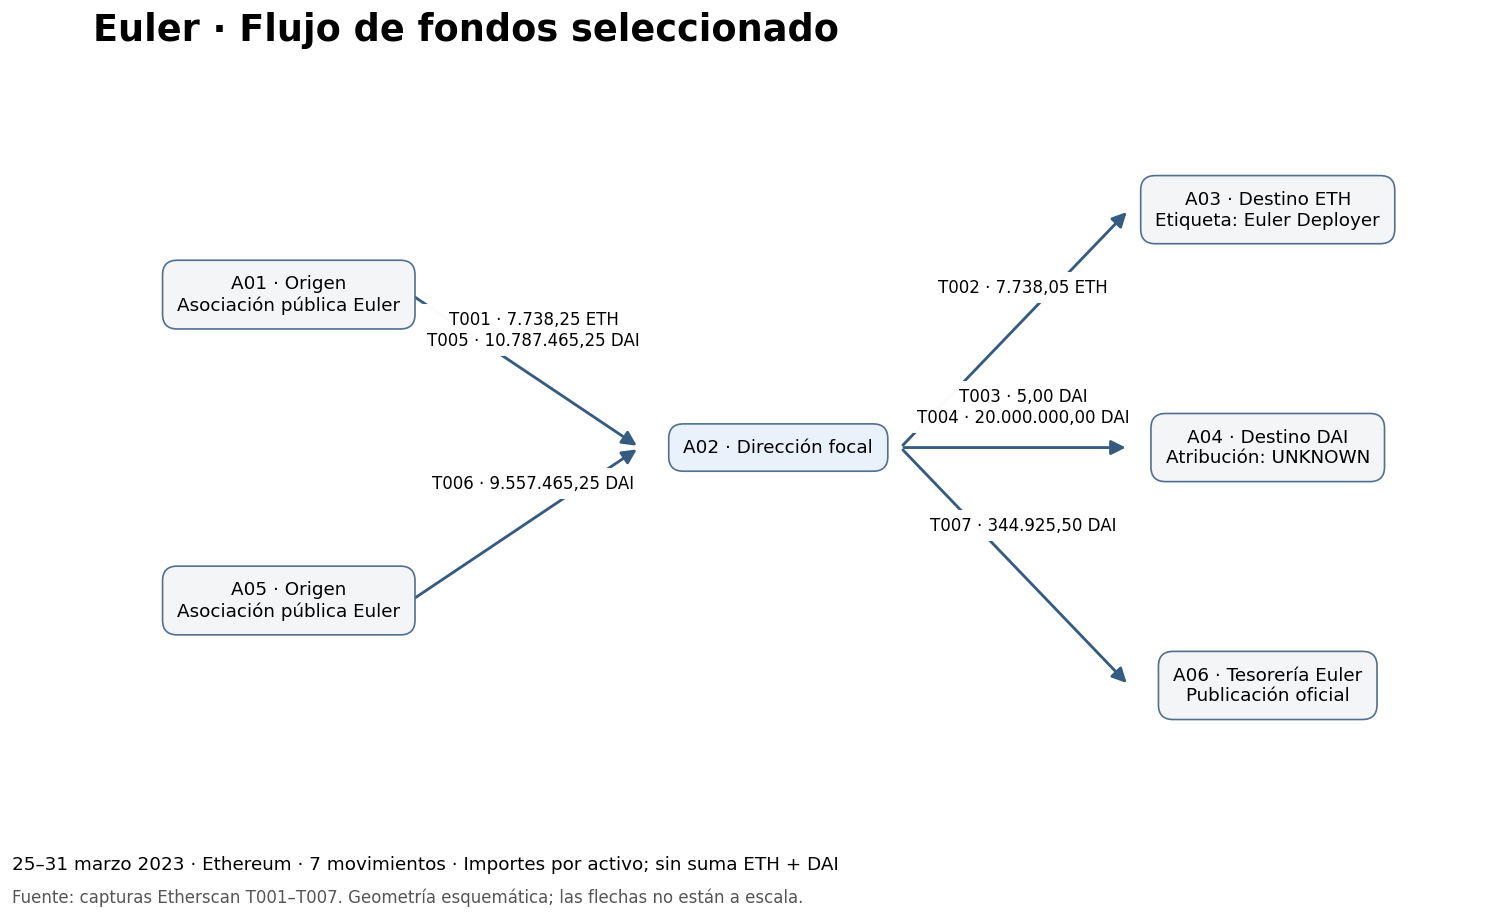

In [8]:
from matplotlib.patches import FancyArrowPatch

posiciones = {'A01':(0,2.4), 'A05':(0,0.6), 'A02':(3,1.5),
              'A03':(6,2.9), 'A04':(6,1.5), 'A06':(6,0.1)}
etiquetas = {'A01':'A01 · Origen\nAsociación pública Euler',
             'A05':'A05 · Origen\nAsociación pública Euler',
             'A02':'A02 · Dirección focal',
             'A03':'A03 · Destino ETH\nEtiqueta: Euler Deployer',
             'A04':'A04 · Destino DAI\nAtribución: UNKNOWN',
             'A06':'A06 · Tesorería Euler\nPublicación oficial'}
fig, ax = plt.subplots(figsize=(15,8))
ax.set_title('Euler · Flujo de fondos seleccionado', loc='left', fontsize=22, weight='bold', pad=25)
for nodo,(x,y) in posiciones.items():
    ax.text(x,y,etiquetas[nodo],ha='center',va='center',fontsize=11,
            bbox=dict(boxstyle='round,pad=0.8',fc='#E9F1FA' if nodo=='A02' else '#F4F5F7',ec='#51708F'),zorder=3)
for (origen,destino),grupo in transacciones.groupby(['from_id','to_id'],sort=False):
    x1,y1=posiciones[origen]; x2,y2=posiciones[destino]
    ax.add_patch(FancyArrowPatch((x1+0.75,y1),(x2-0.85,y2),
                 arrowstyle='-|>',mutation_scale=18,color='#355B80',linewidth=1.7))
    texto='\n'.join(f'{f.id} · {formato(f.amount)} {f.token}' for f in grupo.itertuples())
    ax.text((x1+x2)/2,(y1+y2)/2+0.24,texto,ha='center',va='center',fontsize=10,
            bbox=dict(facecolor='white',edgecolor='none',alpha=0.98),zorder=4)
ax.set(xlim=(-1.2,7.35),ylim=(-0.7,3.65)); ax.axis('off')
fig.text(0.08,0.06,'25–31 marzo 2023 · Ethereum · 7 movimientos · Importes por activo; sin suma ETH + DAI',fontsize=11)
fig.text(0.08,0.025,'Fuente: capturas Etherscan T001–T007. Geometría esquemática; las flechas no están a escala.',fontsize=10,color='#555555')
fig.savefig(SALIDAS/'flujo_fondos.png',dpi=170,bbox_inches='tight')
plt.show()

El diagrama conserva las dos entradas distintas A01 → A02 (ETH y DAI) y las dos salidas A02 → A04 (ambas DAI). Una arista de ETH seguida de una de DAI **no demuestra un swap**. El contrato del token no se clasifica como DEX.

### Conciliación visual DAI

Barras a escala con origen cero. La salida de 5 DAI es demasiado pequeña para distinguirse a esta escala y se identifica expresamente en la anotación y en la cronología.

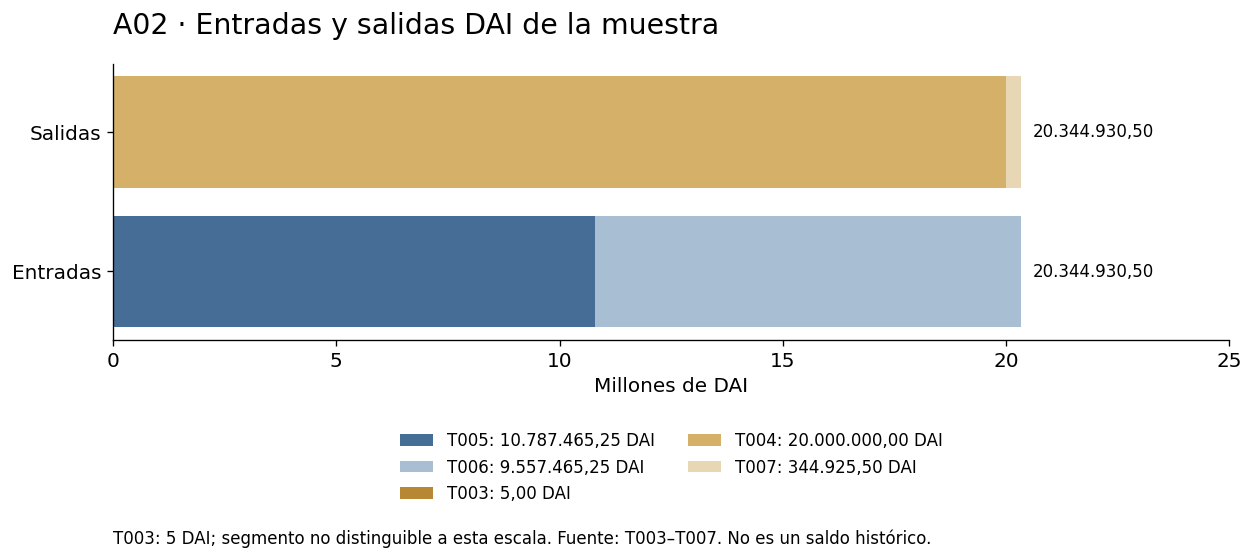

In [9]:
dai = transacciones[transacciones['token'].eq('DAI')]
fig,ax = plt.subplots(figsize=(12,4.6))
colores={'T005':'#456D95','T006':'#A7BED3','T003':'#B78734','T004':'#D5B069','T007':'#E7D7B5'}
for y,(tipo,mascara) in enumerate([
    ('Entradas',dai['to_id'].eq(FOCAL)), ('Salidas',dai['from_id'].eq(FOCAL))]):
    acumulado=0
    for fila in dai[mascara].itertuples():
        ancho=float(fila.amount)/1_000_000  # Solo visualización; los cálculos usan Decimal.
        ax.barh(tipo,ancho,left=acumulado,color=colores[fila.id],label=f'{fila.id}: {formato(fila.amount)} DAI')
        acumulado+=ancho
    ax.text(acumulado+0.25,y,formato(sum(dai.loc[mascara,'amount'], Decimal('0'))),va='center',fontsize=10)
ax.set_xlim(0,25)
ax.set_xlabel('Millones de DAI')
ax.set_title('A02 · Entradas y salidas DAI de la muestra',loc='left',fontsize=17,pad=18)
ax.spines[['top','right']].set_visible(False)
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.28),ncol=2,frameon=False,fontsize=10)
fig.text(0.125,0.01,'T003: 5 DAI; segmento no distinguible a esta escala. Fuente: T003–T007. No es un saldo histórico.',fontsize=10)
fig.subplots_adjust(bottom=0.38)
fig.savefig(SALIDAS/'conciliacion_dai.png',dpi=170,bbox_inches='tight')
plt.show()

## 10. Evaluación de atribuciones

Los IDs A01–A06 son internos de este proyecto. Evitan depender de etiquetas como «Exploiter 2», que cambian según el proveedor. La columna de confianza evalúa exclusivamente la atribución descrita; la identidad de las personas permanece desconocida.

In [10]:
for fila in atribuciones.itertuples():
    texto = f'**{fila.id} — {fila.attribution} · {fila.confidence}**'
    texto += '  ' + chr(10) + f'`{fila.address}`'
    texto += '  ' + chr(10) + f'{fila.basis}. [Fuente]({fila.source})'
    display(Markdown(texto))

**A01 — Asociación pública con el incidente Euler · HIGH CONFIDENCE**  
`0xb66cd966670d962c227b3eaba30a872dbfb995db`  
Dirección completa en Appendix A; captura T001: Euler Finance Exploiter 2. [Fuente](https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption)

**A02 — Asociación pública con el incidente Euler · HIGH CONFIDENCE**  
`0xa1b44d4b5b4c361f51e029b81bf2db9cf4d8e676`  
Dirección completa en Appendix A; movimientos T001–T007. [Fuente](https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption)

**A03 — Euler: Deployer · HIGH CONFIDENCE**  
`0xee009faf00cf54c1b4387829af7a8dc5f0c8c8c5`  
Etiqueta visible en captura T002; no prueba de identidad personal. [Fuente](https://etherscan.io/tx/0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d)

**A04 — Sin atribución validada · UNKNOWN**  
`0x0d1b0c32b52583fd155ea6a2df10214270da9843`  
Receptor económico en T003/T004; dirección completa aportada manualmente. [Fuente](https://etherscan.io/tx/0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b)

**A05 — Asociación pública con el incidente Euler · HIGH CONFIDENCE**  
`0x46e0be2df97dac791fc8e30cf2b2e4f58c50cf55`  
Dirección completa en Appendix A; origen en captura T006. [Fuente](https://www.coinbase.com/blog/euler-compromise-investigation-part-2-the-redemption)

**A06 — Euler DAO Treasury · CONFIRMED**  
`0xcad001c30e96765ac90307669d578219d4fb1dce`  
Dirección publicada por Euler Foundation; captura T007: Euler Multisig 2; dirección completa aportada manualmente. [Fuente](https://euler.foundation/euler-DAO/treasury)

## 11. Hallazgos, exposición y posibles señales de alerta

| ID | Categoría | Hallazgo y evidencia | Interpretación prudente |
|---|---|---|---|
| H01 | FACT | T005 y T006 ingresan 10.787.465,25 y 9.557.465,25 DAI en A02 | Dos orígenes directos distintos en la muestra |
| H02 | INFERENCE | A02 recibe de dos orígenes y envía DAI a dos destinos | Consolidación y redistribución local; fan-in/fan-out pequeño, sin conclusión de ocultamiento |
| H03 | FACT | T003 y T004: 5 y 20.000.000 DAI al mismo receptor, separados por 216 segundos | Secuencia de importe pequeño seguido de importe grande |
| H04 | HYPOTHESIS | T003 podría ser una prueba antes de T004 | También podrían ser pagos independientes; falta mensaje, instrucción o evidencia operativa |
| H05 | ATTRIBUTION | A01, A02 y A05 aparecen en el apéndice de Coinbase sobre Euler | Asociación pública con el incidente; no identidad personal ni prueba autónoma de culpabilidad |
| H06 | ATTRIBUTION | A06 es la dirección publicada como tesorería Euler; T007 envía 344.925,50 DAI | Compatible con devolución hacia Euler; no acredita recuperación total ni destino final para usuarios |
| H07 | FACT | Entradas DAI = salidas DAI en la muestra | Conciliación de movimientos seleccionados; no balance completo |
| H08 | INFERENCE | A01 → A02 → A04/A06 forma caminos dirigidos y temporalmente compatibles | Conectividad indirecta con A01; no cuantificación de contaminación ni de propiedad |

### Exposición directa e indirecta

A02 presenta interacción directa con A01 y A05 mediante entradas DAI, además de la entrada ETH de A01. A04 y A06 reciben directamente de A02; respecto de A01 existe un camino de dos saltos en DAI. A03 recibe ETH directamente de A02 y tiene un camino de dos saltos desde A01. Como A02 también está asociada públicamente al incidente, sus destinatarios tienen asimismo contacto directo con una dirección con esa atribución.

La exposición aquí describe **relaciones observadas**, no responsabilidad ni una puntuación de riesgo. Recibir una devolución puede producir exposición transaccional a una dirección vinculada a un incidente sin implicar participación en él. La fungibilidad de DAI, el alcance parcial y posibles movimientos omitidos impiden atribuir cada unidad saliente a un origen concreto.

### Lectura AML / Financial Crime

Los importes elevados, la procedencia públicamente asociada a un incidente y la redistribución entre direcciones justifican contextualización adicional en un análisis de caso. La secuencia de 216 segundos es temporalmente cercana, pero por sí sola no permite llamar «rápido» a todo el recorrido: el tramo ETH seleccionado dura más de dos días.

No se concluye **layering**, lavado de activos, peel chain, uso de mixer, DEX, bridge, chain hopping ni depósito en un exchange a partir de estas siete operaciones. No se asigna una puntuación AML sin una metodología definida. El contexto de devolución es una explicación relevante que debe considerarse junto a cualquier señal de alerta.

### Qué haría un analista de un exchange si apareciera una alerta comparable

Primero contrastaría el hash y la dirección con datos internos autorizados para determinar si existe realmente una cuenta cliente y si se trata de depósito, retiro o devolución. Después revisaría origen declarado de fondos, evidencia del incidente y contexto de la contraparte, preservando la evidencia y escalando conforme a sus procedimientos. Este proyecto no dispone de KYC ni de registros internos, y **no identifica una cuenta de exchange**.

## 12. Limitaciones y explicaciones alternativas

- **Selección parcial:** siete operaciones alrededor de A02. No se revisó exhaustivamente todo el historial ni se acreditó que no hubiera otros movimientos.
- **Capturas y transcripción:** los datos se reproducen desde evidencia visual. No hay recibos RPC, logs crudos, índices de evento ni verificación independiente de unidades mínimas. Los destinatarios abreviados dependen también de direcciones copiadas por el investigador.
- **Atribución externa:** etiquetas de Etherscan e investigaciones públicas pueden cambiar o contener errores. La publicación actual de A06 no documenta por sí sola su configuración histórica. A04 sigue sin identificar.
- **Activos y comisiones:** los importes visibles no se valoran en USD; las comisiones están incompletas y no se usan para afirmar saldos residuales.
- **Intención y control:** no hay evidencia suficiente para asignar control común, motivaciones o identidades. Un envío pequeño previo puede ser una prueba o una operación independiente.
- **Recuperación:** transferir a una dirección atribuida a Euler es compatible con devolución, pero no acredita por sí solo el acuerdo jurídico, la recuperación de todos los fondos ni su distribución final a afectados.
- **Red:** la forma de estrella responde al muestreo alrededor de A02. Las métricas no describen la red Ethereum completa.
- **Reproducción:** ejecutar este notebook reproduce tablas y figuras de una transcripción fija, no la adquisición original desde un nodo. Revalidar los hashes requiere consultar los enlaces o un proveedor Ethereum.

## 13. Conclusión y cierre del caso acotado

El recorrido seleccionado muestra recepción y redistribución de DAI en A02, una secuencia de dos pagos al mismo destino y transferencias hacia direcciones atribuidas a Euler. El resultado más sólido es la reconstrucción verificable de movimientos, separada de sus interpretaciones. A04 permanece desconocida y las identidades de controladores no se establecen.

**Estado: versión 1.0 cerrada para el alcance de siete operaciones.** Es publicable como portfolio educativo de tracing manual y análisis asistido, con sus limitaciones explícitas. No se presenta como investigación completa del hack ni como dictamen de actividad ilícita. Una futura versión podría añadir recibos RPC y log indexes, o revisar el tramo posterior de A04, sin alterar lo que esta versión afirma.

## 14. Exportación reproducible

Esta celda genera el dataset, las atribuciones, el manifiesto de evidencia y los grafos. GraphML conserva importes como texto, evitando mezclar activos o perder precisión. El notebook ya contiene las figuras y capturas para su lectura independiente.

In [11]:
exportacion = transacciones.copy()
exportacion['timestamp'] = exportacion['timestamp'].dt.strftime('%Y-%m-%dT%H:%M:%SZ')
exportacion['amount'] = exportacion['amount'].map(str)
exportacion['fee_eth'] = exportacion['fee_eth'].map(lambda x: str(x) if x is not None else None)
exportacion.to_csv(SALIDAS/'transacciones.csv',index=False)
atribuciones.to_csv(SALIDAS/'direcciones.csv',index=False)
pd.DataFrame(manifiesto).to_csv(SALIDAS/'manifiesto_evidencia.csv',index=False)
metricas.to_csv(SALIDAS/'metricas_dai.csv',index=False)
nx.write_graphml(grafo,SALIDAS/'grafo_transacciones.graphml')
(SALIDAS/'versiones.json').write_text(json.dumps(versiones,indent=2),encoding='utf-8')

# Relectura: comprobar que la exportación CSV conserva hashes e importes.
relectura = pd.read_csv(SALIDAS/'transacciones.csv',dtype=str,keep_default_na=False)
assert relectura['tx_hash'].tolist() == exportacion['tx_hash'].tolist()
assert relectura['amount'].map(Decimal).tolist() == transacciones['amount'].tolist()
print('Exportación terminada. Archivos en:', str(SALIDAS))

Exportación terminada. Archivos en: salidas_euler


## 15. Apéndice: evidencia transaccional

Las capturas siguientes son las aportadas durante la investigación. Se preservan como imágenes adjuntas del notebook para que este sea autónomo. Los anuncios, equivalentes USD y tiempos relativos del explorador no son datos usados en el análisis. Las tablas anteriores utilizan la hora absoluta UTC y el importe del activo.

### T001 · A01 → A02 · 7738.25 ETH

**Hash:** `0x79c10cf538667a0a7de40ce54d2444c9e9e17b5c62b321e739020df0015baeda`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0x79c10cf538667a0a7de40ce54d2444c9e9e17b5c62b321e739020df0015baeda)  
**Evidencia original:** `image(20261024-173910).png`  
**SHA-256:** `1590a2d90c47e3397eda97870ba3ca09a1ef54e37ae751eafa0c957ca8b49129`

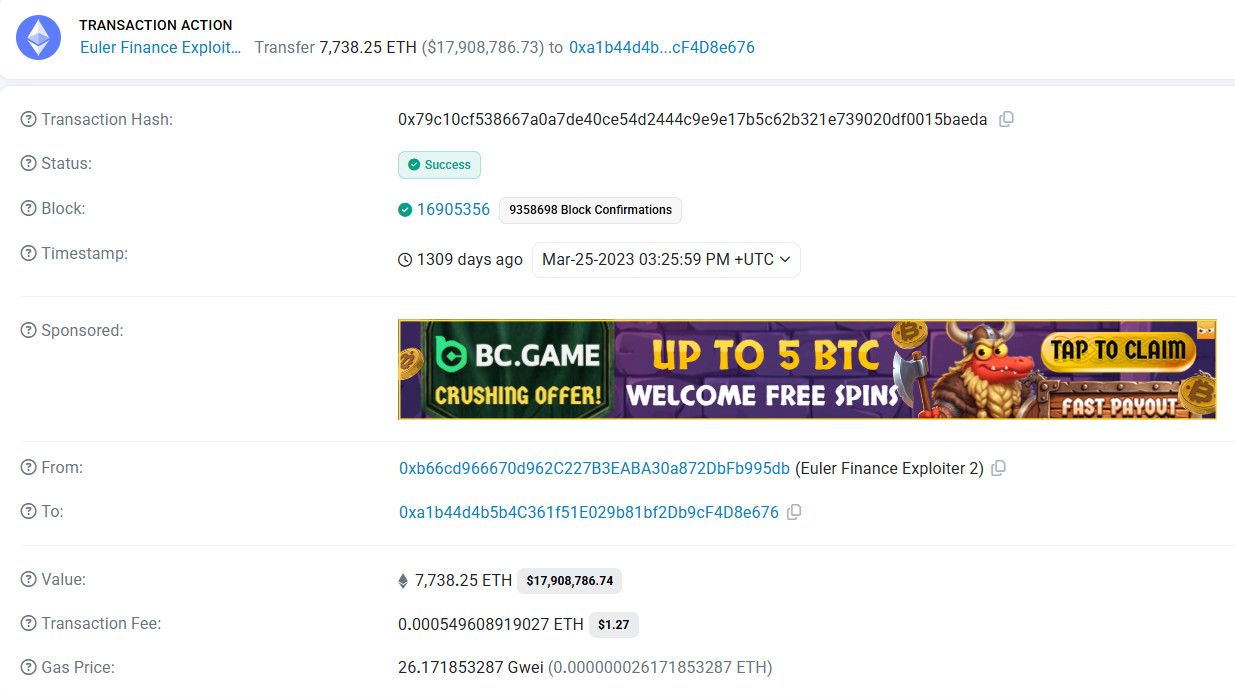

### T002 · A02 → A03 · 7738.05 ETH

**Hash:** `0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0xe3f67f8e50042f09a3d9b6873bd15c14fa8b8176cfa1069bc1d3ab71e4b3fd0d)  
**Evidencia original:** `image(20261024-181616).png`  
**SHA-256:** `4fdc0153e86d98c7dab8cb08433202cbc2d2e344be9475a369ced6d1b8924053`

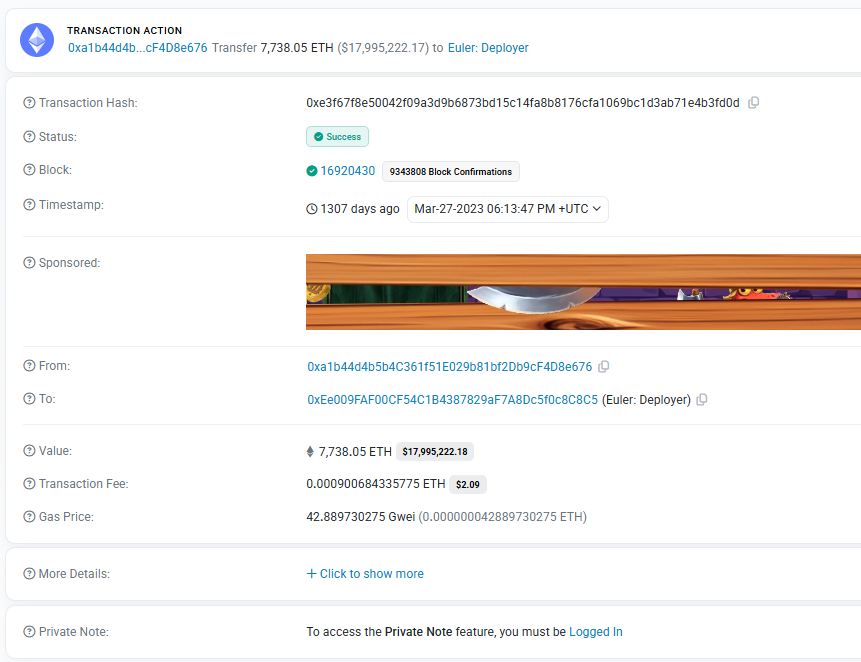

### T003 · A02 → A04 · 5 DAI

**Hash:** `0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0x61e6fa0a064e51320778e92abb475fc7ae06dea0554c969588f4d7ed31d9b42b)  
**Evidencia original:** `image(20261024-184100).png`  
**SHA-256:** `2d4917caf15f9a37432ce1d58123c78c2bbafbcba398d470b029f2b36c582827`

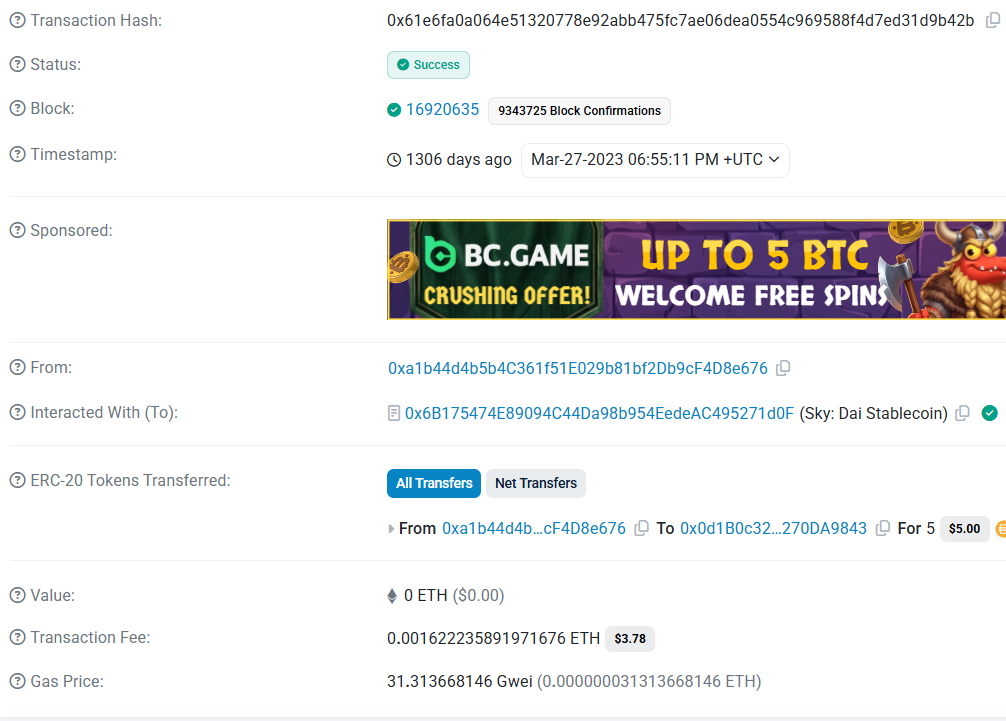

### T004 · A02 → A04 · 20000000 DAI

**Hash:** `0x3d0b3a04a7031841b44c94b4f9cccdc397b0f6e97f7cc2ecfcc3abe8732a995f`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0x3d0b3a04a7031841b44c94b4f9cccdc397b0f6e97f7cc2ecfcc3abe8732a995f)  
**Evidencia original:** `image(20261024-190128).png`  
**SHA-256:** `78a650b17c66a49ef748d824543ff5435f60adfd11e7a3386b9d24e796a06a29`

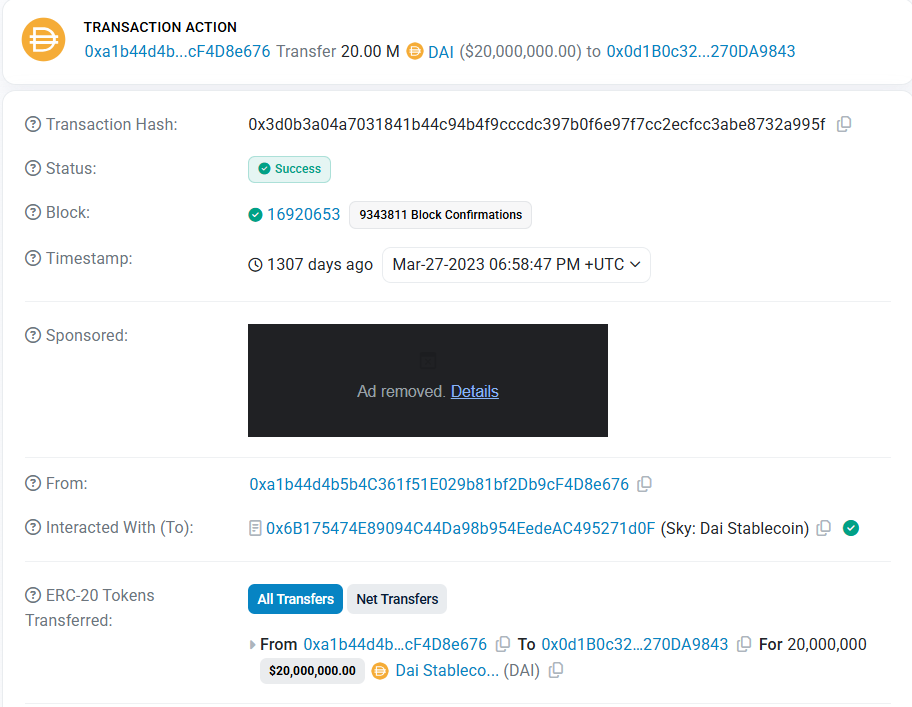

### T005 · A01 → A02 · 10787465.25 DAI

**Hash:** `0x7e606bd1f8ef29cf6dc86c9c48307172985536b2039d41b2f1e672b99bbd1f78`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0x7e606bd1f8ef29cf6dc86c9c48307172985536b2039d41b2f1e672b99bbd1f78)  
**Evidencia original:** `image(20261024-190733).png`  
**SHA-256:** `385028d1a44d73cbd487d9d882cbb8a6f1acaa417e8d5c6727ef0c162aef0ad1`

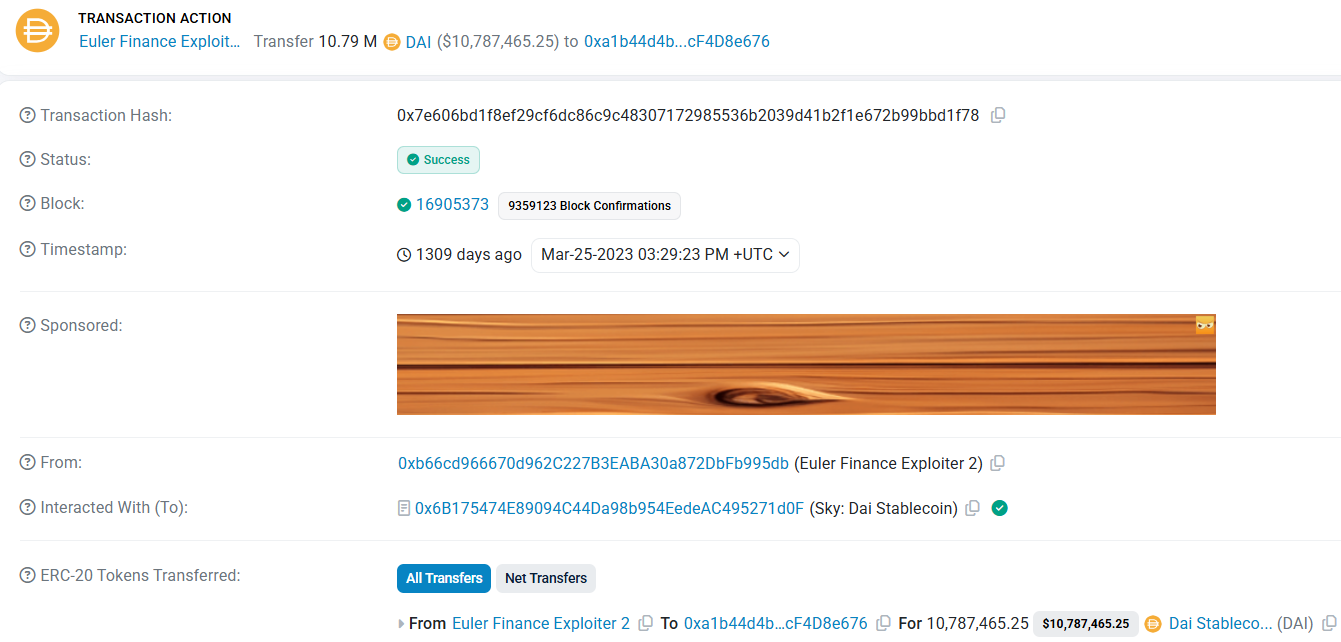

### T006 · A05 → A02 · 9557465.25 DAI

**Hash:** `0x79d5a1f873c52942cc1eb681ef8f6b1005e3fcfa48db5b66e63962b6696e4845`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0x79d5a1f873c52942cc1eb681ef8f6b1005e3fcfa48db5b66e63962b6696e4845)  
**Evidencia original:** `image(20261024-191100).png`  
**SHA-256:** `1c52bf7815c08e795d9cecfa77d2b4480341033f5c2d8548cabb6c45b7b11ba9`

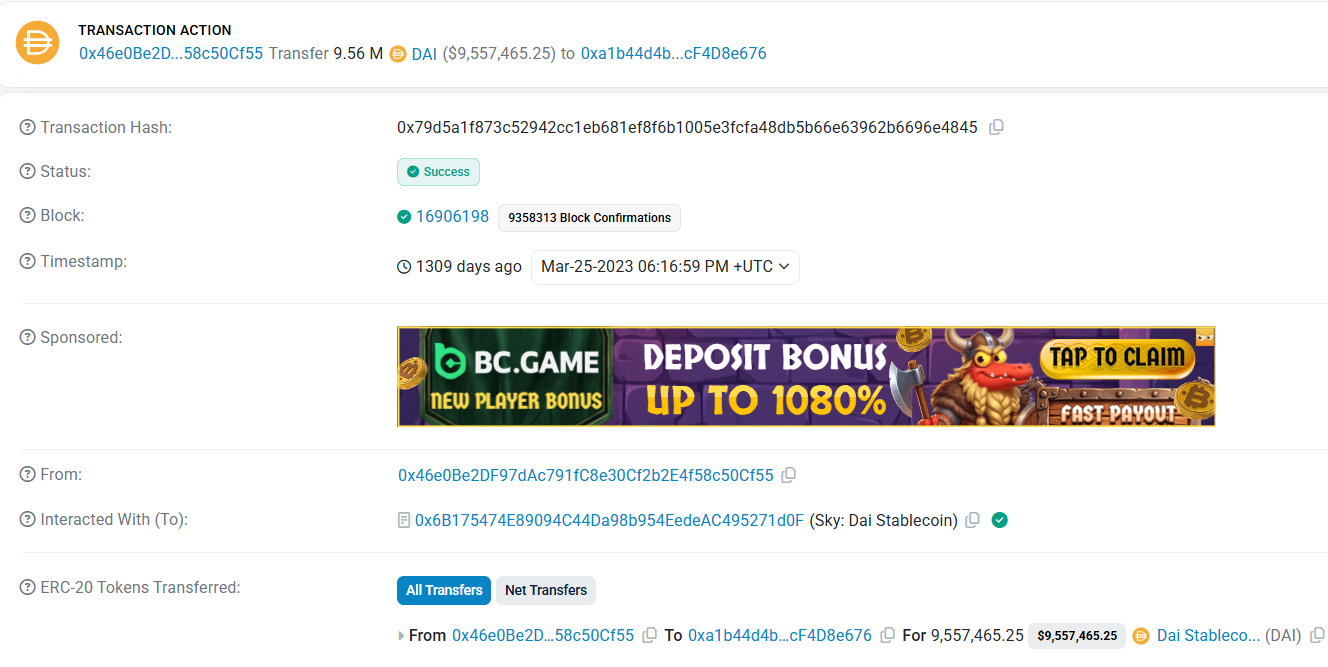

### T007 · A02 → A06 · 344925.50 DAI

**Hash:** `0x7debdb60baabc71c87b25ab0213dc01d0b738050bc00f22397aeb0666f0e8334`  
[Ver transacción en Etherscan](https://etherscan.io/tx/0x7debdb60baabc71c87b25ab0213dc01d0b738050bc00f22397aeb0666f0e8334)  
**Evidencia original:** `image(20261024-231328).png`  
**SHA-256:** `fbbb94101917637da9b2b76353ec6da1605163a9cef906935d58a750cccc3df0`

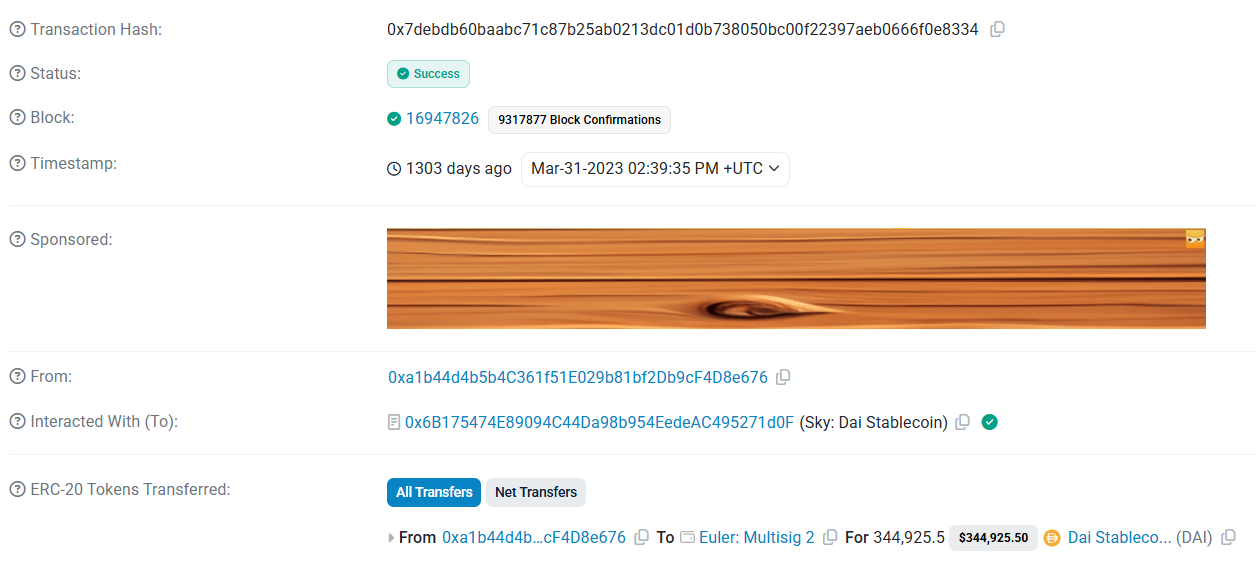

## 16. Guía para defender el proyecto

1. **¿Qué hiciste manualmente?** Revisé transacciones en Etherscan y aporté capturas y direcciones; utilicé asistencia para estructurar, programar y documentar el análisis.
2. **¿Por qué no llega el DAI al contrato que figura en To?** La transacción llama al contrato del token; el receptor económico se lee en la transferencia ERC-20.
3. **¿Por qué MultiDiGraph?** T003 y T004 son dos movimientos diferentes entre el mismo par; un grafo simple puede sobrescribirlos.
4. **¿Por qué no afirmás lavado?** Los patrones no demuestran intención; el contexto de devolución es relevante y las identidades no están establecidas.
5. **¿Por qué neto cero no significa saldo cero?** Solo concilié movimientos seleccionados; faltan saldo inicial e historial completo.
6. **¿Qué mejorarías con más tiempo?** Incorporaría recibos y logs de un proveedor RPC, validaría unidades mínimas y ampliaría de forma controlada el destino A04.

Estas respuestas describen el alcance real. Antes de presentarlo, conviene ejecutar las celdas y explicar con palabras propias los cálculos, sin atribuirse uso de herramientas comerciales ni experiencia laboral que el proyecto no acredita.